In [1]:
library(MASS)
library(ggplot2)
library(dplyr)
source("decision_plot.R")


Attaching package: 'dplyr'


The following object is masked from 'package:MASS':

    select


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




In [17]:
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}

In [3]:
my_accuracy <- function(preds, reference, print_confmat=FALSE){
  confusion_mat <- table(preds, reference)
  acc <- (confusion_mat %>% diag %>% sum) / sum(confusion_mat)
  
  if(print_confmat){
    cat("\nConfusion matrix:\n")
    print(confusion_mat)
  }
  cat("\n", sprintf("Accuracy: %s", acc), "\n")
}

In [4]:
life_data <- read.csv("weight-height.csv")

# height in inches, weight in pounds, transform to cm and kg
life_data <- life_data %>%
  mutate(Height = Height * 2.54,
         Weight = life_data$Weight * 0.454,
         Gender = as.factor(Gender))

glimpse(life_data)

Rows: 10,000
Columns: 3
$ Gender <fct> Male, Male, Male, Male, Male, Male, Male, Male, Male, Male, Mal~
$ Height <dbl> 187.5714, 174.7060, 188.2397, 182.1967, 177.4998, 170.8227, 174~
$ Weight <dbl> 109.81968, 73.68895, 96.58435, 99.89928, 93.68281, 69.10432, 83~


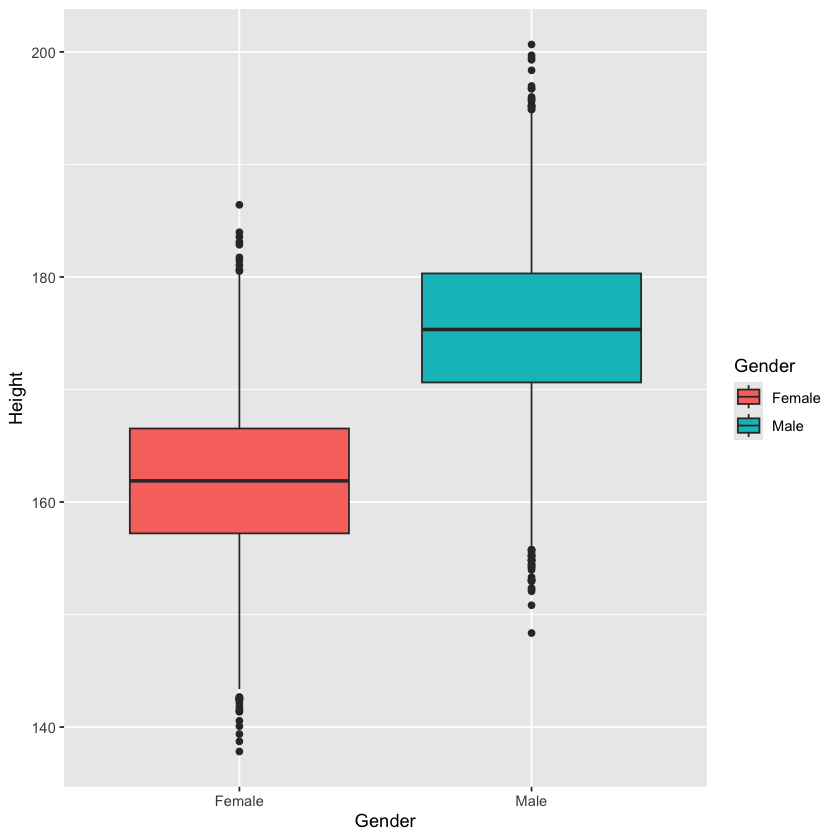

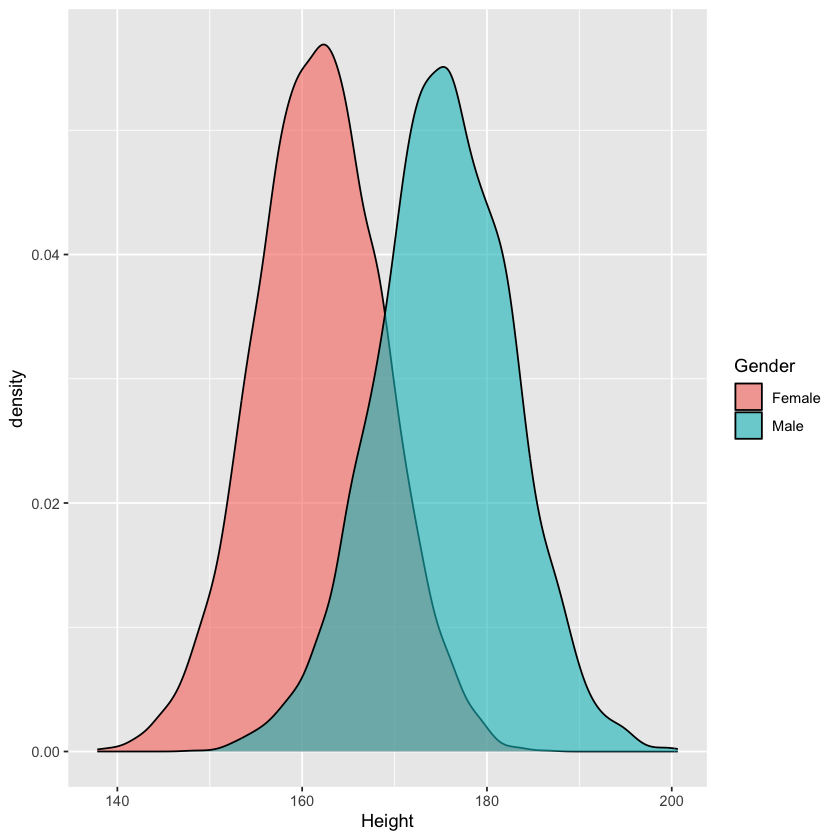

In [5]:
# visualize the data
life_data %>% ggplot(aes(x=Gender, y=Height, fill=Gender)) + 
  geom_boxplot()

life_data %>% ggplot(aes(x=Height, fill=Gender)) +
  geom_density(alpha=0.6)

In [6]:
# run LDA
lda_res <- lda(Gender ~ Height, life_data)
lda_res

# Take look at the predicted posterior probabilities for each gender
gender_pred <- predict(lda_res, life_data)
# View(gender_pred$posterior)

# Check the confusion matrix and the accuracy of predictions
# Note: this is the train accuracy, however, no big risk of overfitting, the sample size is large and the model has only 5 parameters
my_accuracy(gender_pred$class, 
            life_data$Gender,
            print_confmat = TRUE)

Call:
lda(Gender ~ Height, data = life_data)

Prior probabilities of groups:
Female   Male 
   0.5    0.5 

Group means:
         Height
Female 161.8203
Male   175.3269

Coefficients of linear discriminants:
             LD1
Height 0.1415641


Confusion matrix:
        reference
preds    Female Male
  Female   4189  861
  Male      811 4139

 Accuracy: 0.8328 


In [7]:
# Can you guess, what is the threshold value by which we discriminate genders (in a good way)?
# You can use this DF
gender_pred_df <- data.frame(
  Height = life_data$Height,
  Gender_pred = gender_pred$class
)

# Un-comment to view the predictions
# View(gender_pred_df)

lda_decisionBoundary <- gender_pred_df %>% 
  filter(Gender_pred == "Female") %>% 
  dplyr::select(Height) %>% 
  max

paste("The LDA decision boundary in height:", round(lda_decisionBoundary,2))

[1] "The LDA decision boundary in height: 168.57"

In [9]:
# men and women normal distribution parameters
mu_f <- mean(life_data$Height[life_data$Gender == "Female"])
mu_m <- mean(life_data$Height[life_data$Gender == "Male"])
sd_f <- sd(life_data$Height[life_data$Gender == "Female"])
sd_m <- sd(life_data$Height[life_data$Gender == "Male"])
sd_all <- (sd_m + sd_f)/2 # force the LDA assumption of equal variance

# Calculate the posteriors for being a Male for all heights
# HINT: The function dnorm(x, mean, sd) will output the density Pr(x) in the normal distribution characterized by the mean and sd parameters. Accepts also vectors as inputs 'x'
postM <- dnorm(life_data$Height,mu_m,sd_all)/(dnorm(life_data$Height,mu_m,sd_all)+dnorm(life_data$Height,mu_f,sd_all))

# First, check the posterior values
head(postM)
# Male posteriors should match those computed previously, very small deviations can exist
head(gender_pred$posterior)

# Then, turn posteriors into classes (Male/Female; 1/0 are fine too)
gender_pred <- postM > 0.5

# Evaluate the accuracy
my_accuracy(gender_pred, life_data$Gender)

# Now we also know, where did the decision boundary found previously come from. Compare:
(mu_f + mu_m) / 2
lda_decisionBoundary

[1] 0.9942165 0.8404279 0.9951696 0.9756555 0.9182121 0.6477859

,Female,Male
1,0.005810296,0.9941897
2,0.159773209,0.8402268
3,0.004853568,0.9951464
4,0.024423757,0.9755762
5,0.081951918,0.9180481
6,0.352339590,0.6476604



 Accuracy: 0.8328 


[1] 168.5736

[1] 168.5736

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
i Please use `linewidth` instead."


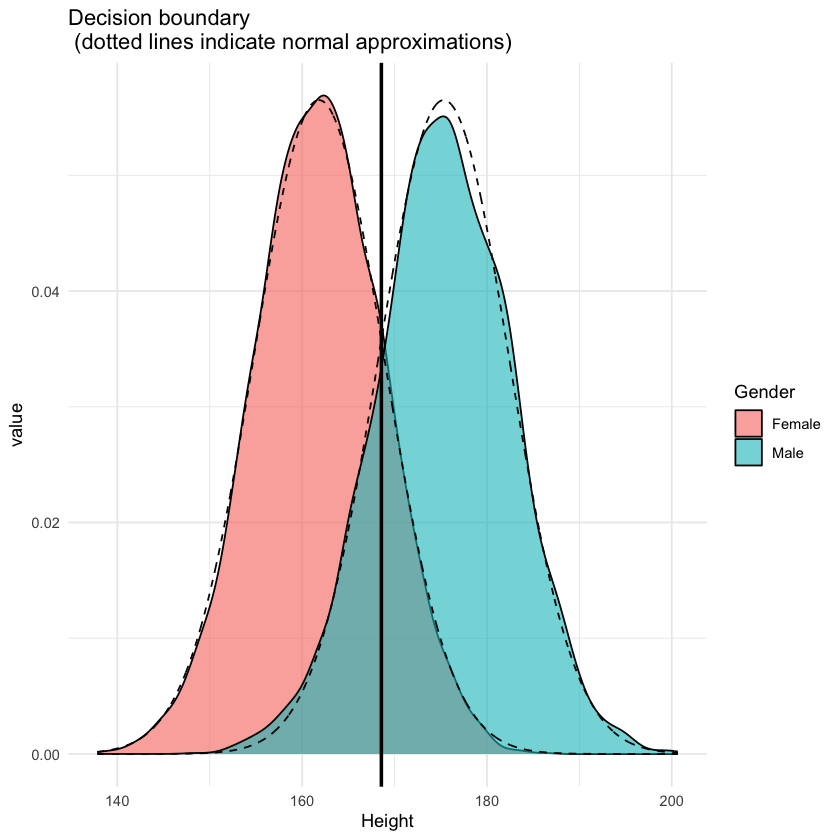

In [10]:
# Create normal approximations of our data (i.e the "ideal data") that LDA internally works with
height_seq <- seq(min(life_data$Height), max(life_data$Height), length.out=nrow(life_data)/2)

ideal_life_data <- data.frame(
  height=height_seq, 
  # Densities of heights under the normality assumption
  Female=dnorm(height_seq, mean=mu_f, sd=sd_all), 
  Male = dnorm(height_seq, mean=mu_m, sd=sd_all)
) 

# Reshape for plotting purposes
ideal_life_data <- ideal_life_data %>%
  reshape2::melt(id.vars="height", variable.name = "Gender")

# Plot the distributions, their normal approximations and the decision boundary (or point in this 1D case)
life_data %>% ggplot(aes(x=Height, fill=Gender)) +
  geom_density(alpha=0.6) +
  geom_line(data = ideal_life_data, aes(x=height, y=value), linetype = 2)  +
  # Add the decision boundary
  geom_vline(xintercept = (mu_f + mu_m) / 2, size=1) +
  ggtitle("Decision boundary\n (dotted lines indicate normal approximations)") +
  theme_minimal()


Call:
lda(Gender ~ ., data = life_data)

Prior probabilities of groups:
Female   Male 
   0.5    0.5 

Group means:
         Height   Weight
Female 161.8203 61.68048
Male   175.3269 84.90736

Coefficients of linear discriminants:
               LD1
Height -0.06766107
Weight  0.15646959


 Accuracy: 0.9193 


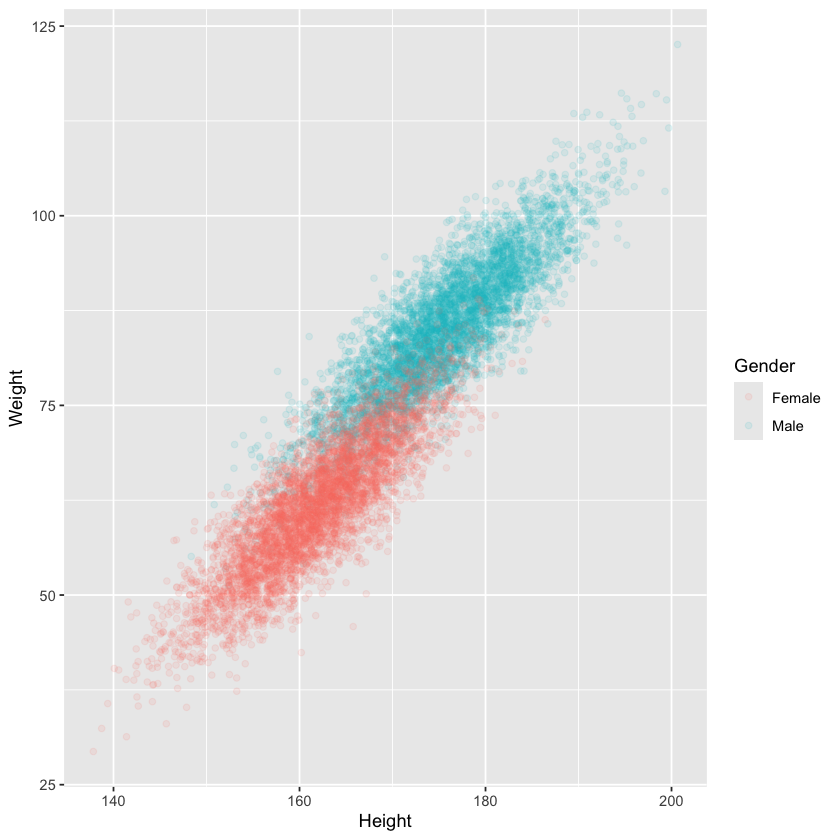

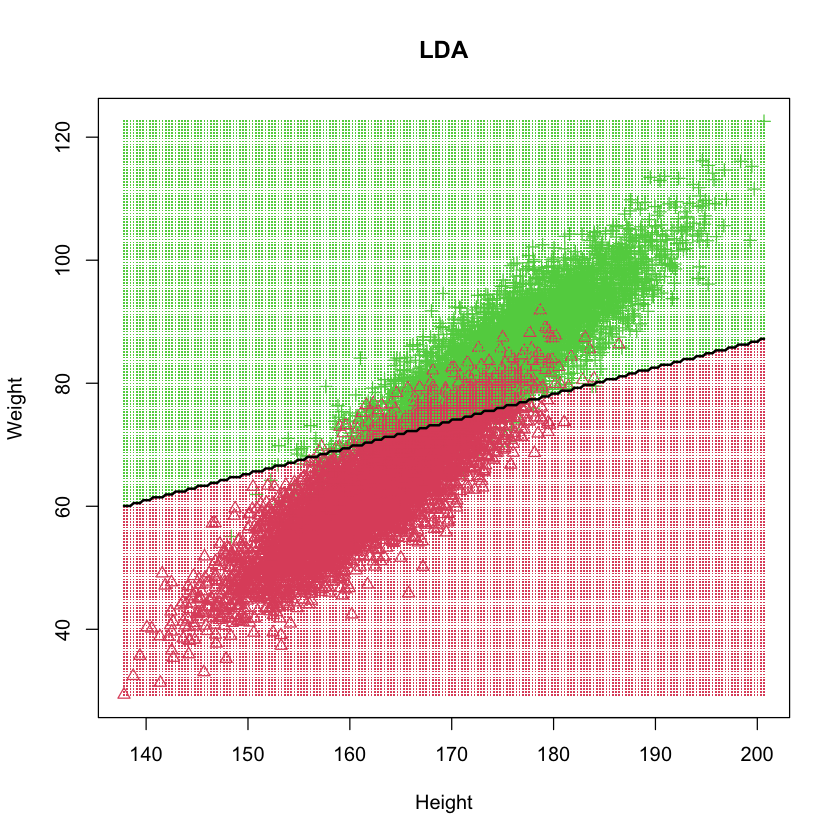

In [18]:
# First, observe, how the multivariate normal distributions of Height + Weight looks
life_data %>%
  ggplot(aes(x=Height, y=Weight, col=Gender)) +
  geom_point(alpha=0.1)

# run LDA function
lda_hw <- lda(Gender ~ ., life_data)
lda_hw

gender_pred <- predict(lda_hw, life_data)$class

# Accuracy, by 8% better than with Height only
my_accuracy(gender_pred, life_data$Gender)
set_plot_defaults()
decisionplot(lda_hw, life_data, class = "Gender", main = "LDA", resolution=200)

In [12]:
# estimate parameters of distributions, substitute them into the Bayes formula
library(mvtnorm)
mu_f <- colMeans(life_data[life_data$Gender=="Female",c(2,3)])
mu_m <- colMeans(life_data[life_data$Gender=="Male",c(2,3)])
cov_f <- cov(life_data[life_data$Gender=="Female",c(2,3)])
cov_m <- cov(life_data[life_data$Gender=="Male",c(2,3)])
cov_avg <- (cov_f + cov_m)/2

# Again, compute the posterior for the samples (simplified by the fact that P(Male)=P(Female))
postM <- dmvnorm(life_data[c(2,3)], mu_m, cov_avg) / 
  (dmvnorm(life_data[c(2,3)], mu_m, cov_avg) + dmvnorm(life_data[c(2,3)], mu_f, cov_avg))
head(postM)

gender_pred <- postM > 0.5

my_accuracy(gender_pred, life_data$Gender)
# The train accuracy of Logistic regression was 0.9194

ERROR: Error in library(mvtnorm): there is no package called 'mvtnorm'


Call:
qda(Gender ~ ., data = life_data)

Prior probabilities of groups:
Female   Male 
   0.5    0.5 

Group means:
         Height   Weight
Female 161.8203 61.68048
Male   175.3269 84.90736


 Accuracy: 0.9192 


, , Female

               1          2
Height 0.1460161 -0.2352167
Weight 0.0000000  0.2195462

, , Male

               1          2
Height -0.137496 -0.2348510
Weight  0.000000  0.2203915

,1,2
1,1.000000e+00,3.917539e-16
2,3.917539e-16,1.000000e+00


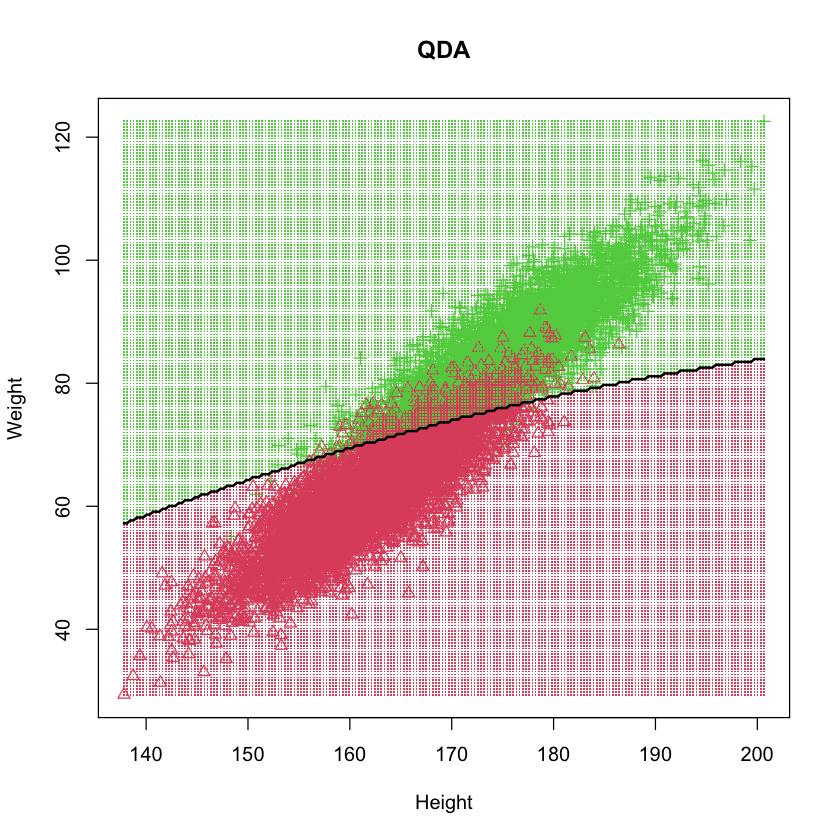

In [19]:
qda_res <- qda(Gender ~ .,life_data)
qda_res

gender_pred <- predict(qda_res, life_data)$class

# Evaluate accuracy
# almost the same train accuracy as LDA, more freedom does not help here
set_plot_defaults()
my_accuracy(gender_pred, life_data$Gender)

decisionplot(qda_res, life_data, class = "Gender", main = "QDA", resolution=200) # decision boundary close to linear
qda_res$scaling # both the genders scale nearly equally (scaling transforms the observations so that within-group covariance matrices are spherical)
var(as.matrix(subset(life_data, Gender=="Male",2:3)) %*% qda_res$scaling[,,"Male"]) # after scaling, the group variances equal 1 and covariances 0

In [14]:
# run Logistic regression - start with a simple Height model
lr <- glm(Gender ~ Height, life_data, family=binomial)
# Look the model - does a coefficient for Height have any (meaningful) interpretation?
# Maybe revise what quantity the Y = B0+B1x1+... represents in the logistic regression
lr

# Obtain the probability of being a Man for train data
lr_prob <- predict(lr, life_data, type="response")
gender_pred <- lr_prob > 0.5

# Compare the 2 calls below. Can you guess how do they differ and how to get from one to the other?
# HINT: Recall, how to get from Y = B0+B1x1+... to the probability
predict(lr, life_data, type="response") %>% head
predict(lr, life_data)   


Call:  glm(formula = Gender ~ Height, family = binomial, data = life_data)

Coefficients:
(Intercept)       Height  
   -45.3001       0.2689  

Degrees of Freedom: 9999 Total (i.e. Null);  9998 Residual
Null Deviance:	    13860 
Residual Deviance: 7542 	AIC: 7546

1         2         3         4         5         6 
0.9941160 0.8416663 0.9950788 0.9755074 0.9184738 0.6517203

1             2             3             4             5 
 5.1296161328  1.6706787812  5.3092777138  3.6845851846  2.4217887572 
            6             7             8             9            10 
 0.6266094627  1.6728484773  1.3747201723  0.4667670820 -1.9660140030 
           11            12            13            14            15 
 3.3188295862  3.6230063526 -1.0715348931  2.0129222775  1.9860586679 
           16            17            18            19            20 
 0.8947165496  4.1539646170 -1.6123895988  2.2567086196  1.0930189488 
           21            22            23            24            25 
 1.0787091284  2.1197063208 -0.1272265674  6.0576400007  1.0637852527 
           26            27            28            29            30 
 1.2350800697  1.8808240919  4.4151900935  0.7414904639  1.4757201504 
           31            32            33            34            35 
 1.5588251180  5.2571743928  3.5461198964  1.9426462983  2.2137835606 
           36            37            38            39            40 
 2.7763018014  1.8716321546  0.5859824317 -0.3606510132 -1.3871285654 
           41            42            43            44            45 
 1.1191952294  3.9976564594 -0.7273449157 -0.1674863239  0.8023221752 
           46            47            48            49            50 
 2.5740676515  1.3086985750  3.9862406204  1.9424390530  4.4626626122 
           51            52            53            54            55 
-1.0604352335  2.6278548960  1.4723295086  0.6797490235  0.4476422276 
           56            57            58            59            60 
 0.1120718857  1.3778212879  3.0313834758  3.3328571843  2.5116368255 
           61            62            63            64            65 
 3.4607350028  2.1965764853  5.1101656201  0.4516977120  3.4711721372 
           66            67            68            69            70 
-0.7212298114  1.3239647024  4.3909653906  1.2045867869  1.7490764436 
           71            72            73            74            75 
 2.0173200264  2.8598168073  2.2728695391  0.8603322064  4.2152910990 
           76            77            78            79            80 
 3.3581665722  3.7379933228  4.0357206662  0.1210026154 -0.2092407907 
           81            82            83            84            85 
 0.8479616662  1.3051011970  5.1153504583  2.3676137186 -0.2566720552 
           86            87            88            89            90 
 3.2393647777  0.1780713342  1.7865188755  1.3036624687  4.0846566365 
           91            92            93            94            95 
 3.7422501862 -0.7500825717  2.9399241238 -1.0950288758  0.5245409870 
           96            97            98            99           100 
-0.8317325901  3.6642729135  0.3396999235  0.0927632929  2.1006442469 
          101           102           103           104           105 
 2.5381414091  0.2787355122 -0.0417301300  1.3610161759  2.5543333278 
          106           107           108           109           110 
 1.6372743883  0.8335507633 -0.0558637093  1.9440404825  0.8697808249 
          111           112           113           114           115 
 2.0195244496  1.2669379200  3.5999796172  1.9540481839  0.6327181522 
          116           117           118           119           120 
 5.0191076884  2.1864764171  1.3494833516  0.9584604860  3.6673654541 
          121           122           123           124           125 
-1.8459812249  1.6292232728  0.4192321590 -2.4778462634  4.0447645404 
          126           127           128           129           130 
 3.1230238035  0.8702852517  3.0498898361  2.0277403681 -0.0631940302 
          131           132           133           134           135 
 0.7899422975 -0.3613799098  3.4884082341  1.4538610180 -1.6031029970 
          136           137           138           139           140 
 3.1867000357  1.2321377470  1.4067374969  1.2024288028  1.2327292451 
          141           142         


Confusion matrix:
       reference
preds   Female Male
  FALSE   4171  845
  TRUE     829 4155

 Accuracy: 0.8326 


[1] "LR decision boundary: 168.498"

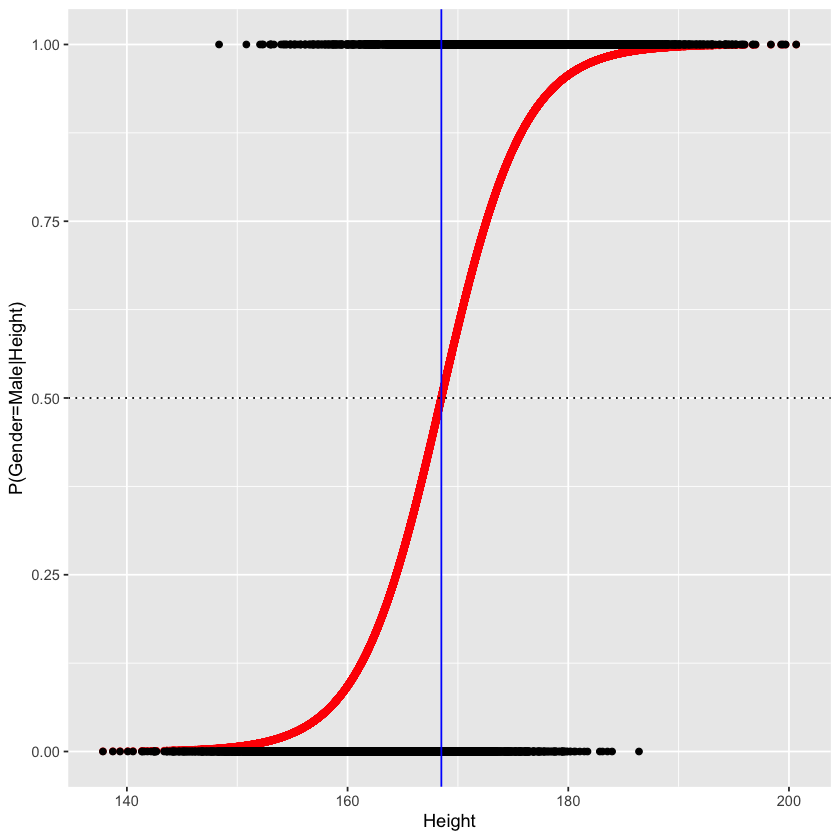

In [15]:
# Evaluate accuracy of Logistic regression
my_accuracy(gender_pred, life_data$Gender, print_confmat = TRUE)

# Prepare data to plot the sigmoid
sigmoid_data <- life_data %>%
  mutate(lr_prob = lr_prob,
         gender_num = as.numeric(Gender) - 1)

# Using the sigmoid data, estimate the decision boundary of the logistic regression
# You will see a better way to analytically find the decision boundary
lr_decisionBoundary <- sigmoid_data %>% filter(lr_prob > 0.5) %>% pull(Height) %>% min() %>% round(digits=3)
# compared to lda_decisionBoundary, a tiny difference exists
sprintf("LR decision boundary: %s", lr_decisionBoundary)

# Plot the sigmoid
sigmoid_data %>%   
  ggplot(aes(x=Height, y=lr_prob)) +
  geom_point(col="red") +
  geom_point(aes(x=Height, y=gender_num)) +
  # Logistic regression decision boundary
  geom_vline(xintercept = lr_decisionBoundary, col="blue") +
  geom_hline(yintercept = 0.5, linetype="dotted") +
  ylab("P(Gender=Male|Height)")


Call:  glm(formula = Gender ~ ., family = binomial, data = life_data)

Coefficients:
(Intercept)       Height       Weight  
     0.6925      -0.1939       0.4369  

Degrees of Freedom: 9999 Total (i.e. Null);  9997 Residual
Null Deviance:	    13860 
Residual Deviance: 4183 	AIC: 4189


 Accuracy: 0.9194 


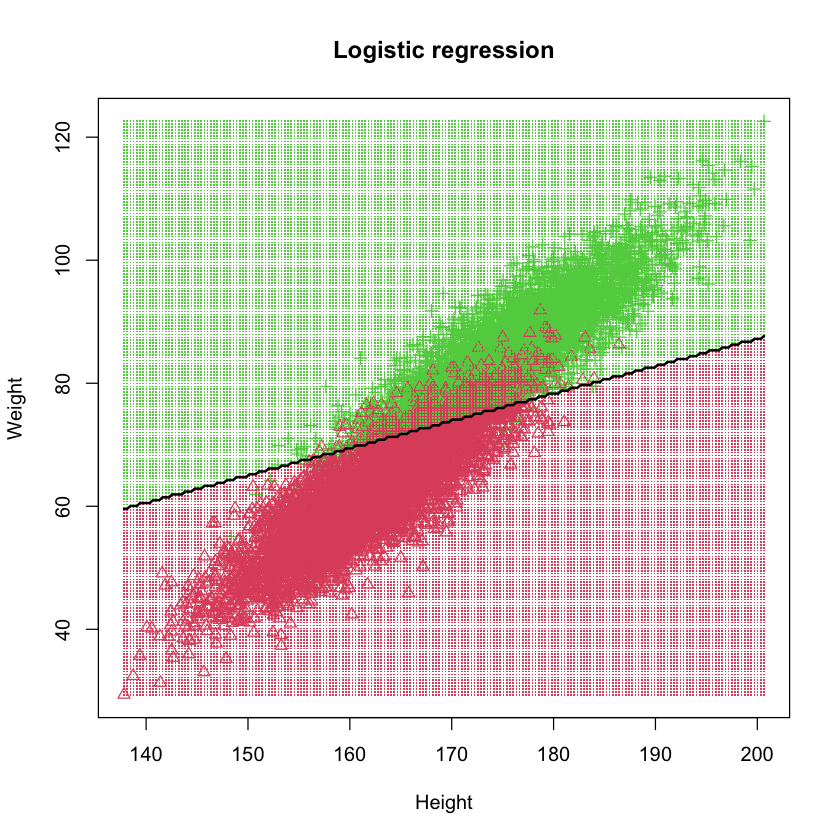

In [20]:
lr_hw <- glm(Gender ~ ., life_data, family=binomial)
lr_hw

# Predict the gender and assess the accuracy
gender_pred <- predict(lr_hw, life_data, type = "response") > 0.5
my_accuracy(gender_pred, life_data$Gender)

# Plotting decision boundary
class(lr_hw) <- c("lr", class(lr_hw)) # a bit of adjusting for plotting the decision boundary
# the decision boundary is linear!
predict.lr <- function(object, newdata, ...)
  predict.glm(object, newdata, type = "response") > .5
  set_plot_defaults()
decisionplot(lr_hw, life_data, class = "Gender", main = "Logistic regression", resolution=200) 

# Question: Why is the logistic regression decision boundary linear? Can you derive the equation?
# HINT: Refer again to the equation of LR. What probability do the points lying on the decision boundary have?